# Description

The fig 2 is divided in several parts ploted in python separatly described below. They were then reassembled and eddited in Canva to facilitate the edditing. 

# Library importation

In [23]:
import sys
sys.path.insert(1, '/home/bricej/MyPythonLibrary/StageM2_IVT/library/')
import domain
from domain import *
from climbas import *
import numpy as np
import geopandas as gpd
import xarray as xr
import pandas as pd
from netCDF4 import Dataset
import dask
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib as mpl
from matplotlib.patches import Rectangle
from shapely.geometry import Polygon, MultiPolygon
import regionmask

# Part 1 : Map of the glacier elevation change (2000-2019)

For more details for the subregions definition : shapefile created and saved in '/home/bricej/MyPythonLibrary/StageM2_IVT/papier/himap_grouped_regions_hugonnet'

For more details for the glacier elevation data, go to : /StageM2_IVT/papier/dh-dt_HIMAPgrouped_2000-2019.ipynb

In [3]:
# shapefile with the polygons of the suberegions
shp = gpd.read_file('/bettik/PROJECTS/pr-regional-climate/bricej/HIMAP_grouped_regions/himap_grouped_regions.shp')

# Glacier elevation change (dh/dt) data
dhdt = pd.read_csv('/bettik/PROJECTS/pr-regional-climate/bricej/paper/dhdt_2000-2019_HIMAPgrouped_regions.csv')

# Merge the regions and the dh/dt data
shp = shp.merge(dhdt,left_on="Primary_ID",right_on="region",how="left")

# Short namze of the subregions
short_name = ['B','CH','HK','TP','Ka','Ku','N','P','PA','SL','TS']

### Figure with the names of the subregions

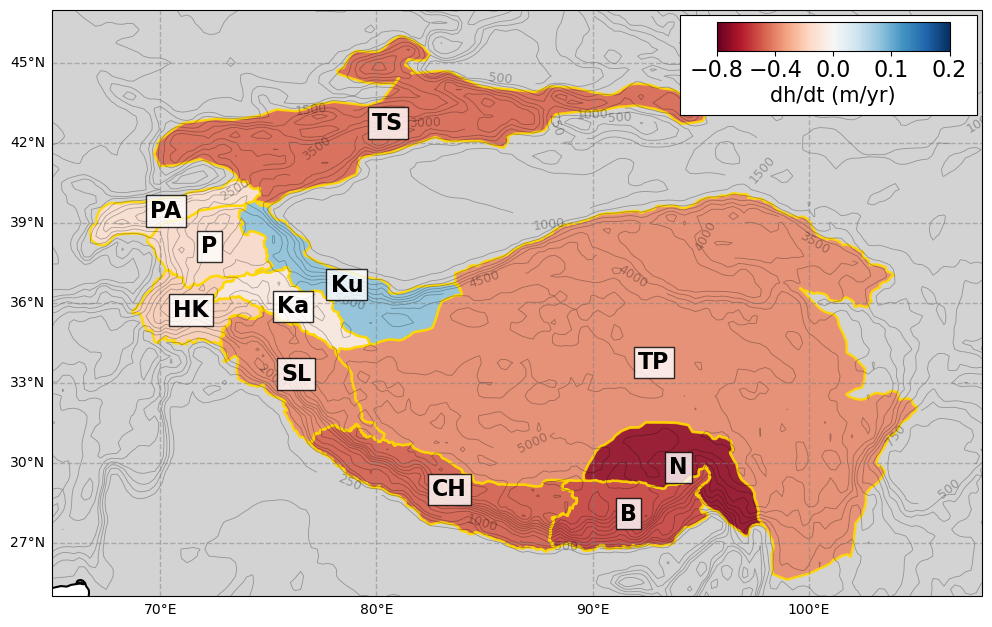

In [4]:
# figure
fig, ax = plt.subplots(figsize=(12, 8),subplot_kw={'projection': ccrs.PlateCarree()})

# Normalisation centrée sur 0
norm = mcolors.TwoSlopeNorm(vmin=-0.8,vcenter=0,vmax=0.2)

# Plot des régions avec shading selon dhdt
shp.plot(column="dhdt",cmap="RdBu", norm=norm,ax=ax,edgecolor="gold",linewidth=1.8,alpha=0.9,legend=False)

ax.coastlines(linewidth=1.5) # coastline
ax.add_feature(cfeature.LAND, facecolor="lightgrey") # land is grey

# Courbes de niveau
elev = xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/bricej/gmted/gmted_on_era5_MA.nc')['elevation']
SH = ax.contour(
    elev.longitude,elev.latitude,elev,
    levels=[250,500,750,1000,1500,2000,2500,3000,
            3500,4000,4500,5000,5500,6000,6500,7000],
    colors="black", linewidths=0.6,alpha=0.3,transform=ccrs.PlateCarree())
ax.clabel(SH, inline=True, fontsize=9, fmt="%d")

# Labels des régions au centre des régions
for idx, row in shp.iterrows():
    centroid = row.geometry.centroid
    ax.text(centroid.x,centroid.y,f"{short_name[idx]}",fontsize=16,fontweight='bold',ha='center',va='center',color='black',
        transform=ccrs.PlateCarree(),zorder=5,bbox=dict(facecolor='white', alpha=0.8, edgecolor='black', pad=3))

# Limit of the figure
bounds = shp.total_bounds
ax.set_extent([65, bounds[2]+3,25, 47], crs=ccrs.PlateCarree())

# Grille lat-lon
gl = ax.gridlines(draw_labels=True,linewidth=1,color='gray',alpha=0.5,linestyle='--')
gl.top_labels = False
gl.right_labels = False

# colorbar for dh/dt
# Colorbar en haut à droite, à l'intérieur de la carte
sm = mpl.cm.ScalarMappable(cmap="RdBu",norm=mcolors.TwoSlopeNorm(vmin=-0.8, vcenter=0, vmax=0.2))
sm.set_array([])

# rectangle blanc derrière la légende
rect = Rectangle(
    (0.675, 0.82),  # position : x, y
    0.32,            # largeur
    0.17,            # hauteur
    transform=ax.transAxes,facecolor="white",edgecolor="black",linewidth=0.8,zorder=10)
ax.add_patch(rect)

# Position : [gauche, bas, largeur, hauteur] en fractions de l'axe
cax = ax.inset_axes([0.715, 0.93, 0.25, 0.048])
cax.set_zorder(11)
cbar = plt.colorbar(sm,cax=cax,orientation="horizontal")
cbar.set_label("dh/dt (m/yr)", fontsize=15, labelpad=3)
cbar.set_ticks([-0.8, -0.4, 0, 0.1, 0.2])
cbar.ax.tick_params(labelsize=16, pad=2)

plt.show()

### Figure without the names of the subregions

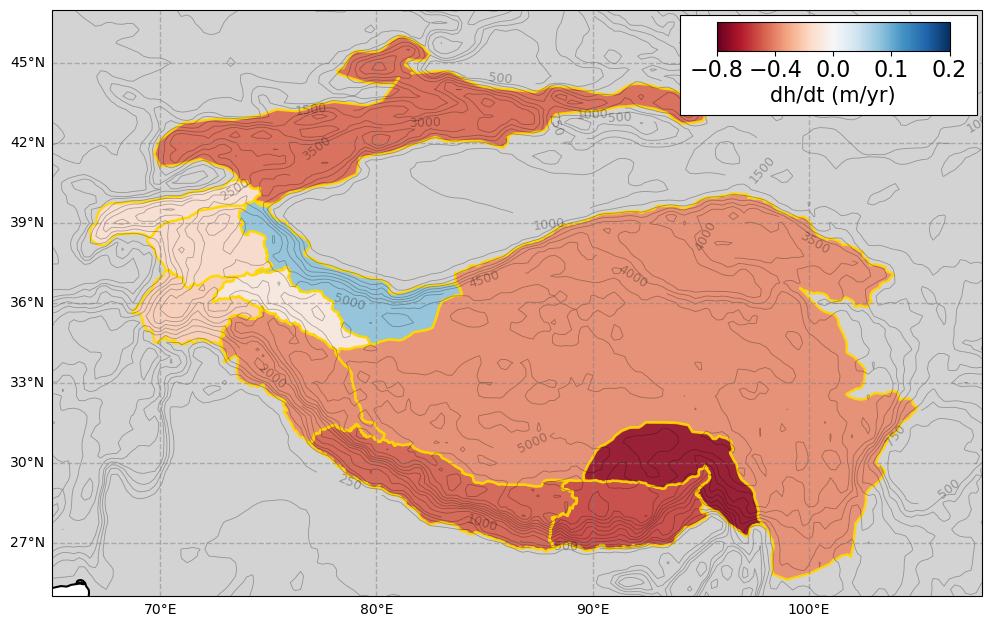

In [5]:
# figure
fig, ax = plt.subplots(figsize=(12, 8),subplot_kw={'projection': ccrs.PlateCarree()})

# Normalisation centrée sur 0
norm = mcolors.TwoSlopeNorm(vmin=-0.8,vcenter=0,vmax=0.2)

# Plot des régions avec shading selon dhdt
shp.plot(column="dhdt",cmap="RdBu", norm=norm,ax=ax,edgecolor="gold",linewidth=1.8,alpha=0.9,legend=False)

ax.coastlines(linewidth=1.5) # coastline
ax.add_feature(cfeature.LAND, facecolor="lightgrey") # land is grey

# Courbes de niveau
elev = xr.open_dataset('/bettik/PROJECTS/pr-regional-climate/bricej/gmted/gmted_on_era5_MA.nc')['elevation']
SH = ax.contour(
    elev.longitude,elev.latitude,elev,
    levels=[250,500,750,1000,1500,2000,2500,3000,
            3500,4000,4500,5000,5500,6000,6500,7000],
    colors="black", linewidths=0.6,alpha=0.3,transform=ccrs.PlateCarree())
ax.clabel(SH, inline=True, fontsize=9, fmt="%d")

# Limit of the figure
bounds = shp.total_bounds
ax.set_extent([65, bounds[2]+3,25, 47], crs=ccrs.PlateCarree())

# Grille lat-lon
gl = ax.gridlines(draw_labels=True,linewidth=1,color='gray',alpha=0.5,linestyle='--')
gl.top_labels = False
gl.right_labels = False

# colorbar for dh/dt
# Colorbar en haut à droite, à l'intérieur de la carte
sm = mpl.cm.ScalarMappable(cmap="RdBu",norm=mcolors.TwoSlopeNorm(vmin=-0.8, vcenter=0, vmax=0.2))
sm.set_array([])

# rectangle blanc derrière la légende
rect = Rectangle(
    (0.675, 0.82),  # position : x, y
    0.32,            # largeur
    0.17,            # hauteur
    transform=ax.transAxes,facecolor="white",edgecolor="black",linewidth=0.8,zorder=10)
ax.add_patch(rect)

# Position : [gauche, bas, largeur, hauteur] en fractions de l'axe
cax = ax.inset_axes([0.715, 0.93, 0.25, 0.048])
cax.set_zorder(11)
cbar = plt.colorbar(sm,cax=cax,orientation="horizontal")
cbar.set_label("dh/dt (m/yr)", fontsize=15, labelpad=3)
cbar.set_ticks([-0.8, -0.4, 0, 0.1, 0.2])
cbar.ax.tick_params(labelsize=16, pad=2)

plt.show()

# Part 2 : Subplots for the differents subregions : Annual Cycle of the sf & t2m short trends (ERA5, 2000-2019)

## Period wanted

In [6]:
iyear = 2000
fyear = 2019

## Subregions with galcier evolution data

In [7]:
domains = ["Tien Shan", "Pamir Alay", "Pamir", "Hindu Kush", "Karakoram", 
           "Kunlun", "Spiti Lahaul", "Central Himalaya","Bhutan", "Nyainqentangla", "Inner TP"]

# Atmospheric variables

In [8]:
variables = ['sf','t2m']

# Short period trends data loading

Monthly trends of the different armospheric variables in the subregions were computed in : /Stage M2/papier/compute_monthly-trends_var_era5_HIMAPgrouped_final_regions.py for t2m & FLH. For tcwv, ivt & sf in : /Stage M2/papier/compute_monthly-percentage_trends_var_era5_HIMAPgrouped_final_regions.py

In [9]:
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'] # month of the year
path = '/bettik/PROJECTS/pr-regional-climate/bricej/paper/' # path to the data

var_trends = {} # dictionnary to store short period data

for var in variables:
    var_trends[var] = {}
    for month in months :
        monthly_trends = pd.read_csv(f'{path}{var}_era5_{month}_trends_HIMAPgrouped_regions_{iyear}-{fyear}.csv')
        var_trends[var][month] = monthly_trends

# stocker valeur de la pente
var_slopes = {}
for var in variables:
    var_slopes[var] = {}
    for dom in domains:
        var_slopes[var][dom] = {}
        for month in months:
            var_slopes[var][dom][month] = var_trends[var][month].loc[var_trends[var][month]['region'] == dom, 'slope'].values[0] * 10 # *10 -> per decade

# stocker valeur de la pvalue
var_pvalue = {}
for var in variables:
    var_pvalue[var] = {}
    for dom in domains:
        var_pvalue[var][dom] = {}
        for month in months:
            var_pvalue[var][dom][month] = var_trends[var][month].loc[var_trends[var][month]['region'] == dom, 'pvalue'].values[0]

# Percentage trend for sf

In [10]:
var_trends2 = {} # dictionnary to store short period data percentage

for var in variables:
    var_trends2[var] = {}
    for month in months :
        if var in ['t2m','FLH']: # normal pour t2m 
            monthly_trends = pd.read_csv(f'{path}{var}_era5_{month}_trends_HIMAPgrouped_regions_{iyear}-{fyear}.csv')
        elif var in ['tcwv','ivt','sf']: # percentage trends for sf
            monthly_trends = pd.read_csv(f'{path}{var}_era5_{month}_percentage_trends_HIMAPgrouped_regions_{iyear}-{fyear}.csv')
        var_trends2[var][month] = monthly_trends

# stocker valeur de la pente
var_slopes2 = {}
for var in variables:
    var_slopes2[var] = {}
    for dom in domains:
        var_slopes2[var][dom] = {}
        for month in months:
            var_slopes2[var][dom][month] = var_trends2[var][month].loc[var_trends2[var][month]['region'] == dom, 'slope'].values[0] * 10 # *10 -> per decade

# stocker valeur de la pvalue
var_pvalue2 = {}
for var in variables:
    var_pvalue2[var] = {}
    for dom in domains:
        var_pvalue2[var][dom] = {}
        for month in months:
            var_pvalue2[var][dom][month] = var_trends2[var][month].loc[var_trends2[var][month]['region'] == dom, 'pvalue'].values[0]

# Saison d'accumulation

Mois qui recoivent plus de 8% du total tp annuel. For more details : /StageM2_IVT/papier/Annual_Cycle_var_mean_1960-2019_HIMAPgrouped_final.py (last cell)

In [11]:
tp_season = {"Tien Shan" : ['Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep'],
        "Pamir Alay" : ['Mar', 'Apr', 'May', 'Jun', 'Jul'],
        "Pamir" : ['Feb', 'Mar', 'Apr', 'May', 'Dec'],
        "Hindu Kush" : ['Feb', 'Mar', 'Apr', 'May', 'Jul', 'Aug'],
        "Karakoram" : ['Feb', 'Mar', 'Apr', 'Jul', 'Aug'],
        "Kunlun" : ['May', 'Jun', 'Jul', 'Aug', 'Sep'],
        "Spiti Lahaul" : ['Feb', 'Mar', 'Apr', 'Jul', 'Aug'],
        "Central Himalaya" : ['Jun', 'Jul', 'Aug', 'Sep'],
        "Bhutan" : ['May', 'Jun', 'Jul', 'Aug', 'Sep'],
        "Nyainqentangla" : ['Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep'],
        "Inner TP" : ['May', 'Jun', 'Jul', 'Aug', 'Sep']}

# for the plot later we associate the number with the month
month_to_num = {
    'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4,
    'May': 5, 'Jun': 6, 'Jul': 7, 'Aug': 8,
    'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12
}

## Annual trends for the subregions

Annual trends of the different armospheric variables in the subregions were computed in : /Stage M2/papier/compute_annual-trends_var_era5_HIMAPgrouped_final_regions.py for t2m & FLH. For tcwv, ivt & sf in : /Stage M2/papier/compute_annual-percentage_trends_var_era5_HIMAPgrouped_final_regions.py

In [12]:
data_annual = {}
variables = ['t2m','sf']

for var in variables:
    if var in ['t2m','FLH','vimd', 'R']: # classic trend with t2m
        data_var = pd.read_csv(f'/bettik/PROJECTS/pr-regional-climate/bricej/paper/{var}_era5_trends_HIMAPgrouped_regions_{iyear}-{fyear}.csv')
        data_var = data_var[["region", "slope", "pvalue"]]
        data_var["slope"] = data_var["slope"] * 10
        data_annual[var] = data_var

    elif var in ['tcwv','ivt','tp','sf','rf']: # percentage trend for sf
        data_var = pd.read_csv(f'/bettik/PROJECTS/pr-regional-climate/bricej/paper/{var}_era5_percentage_trends_HIMAPgrouped_regions_{iyear}-{fyear}.csv')
        data_var = data_var[["region", "slope", "pvalue"]]
        data_var["slope"] = data_var["slope"] * 10
        data_annual[var] = data_var

## Plot of the subplots

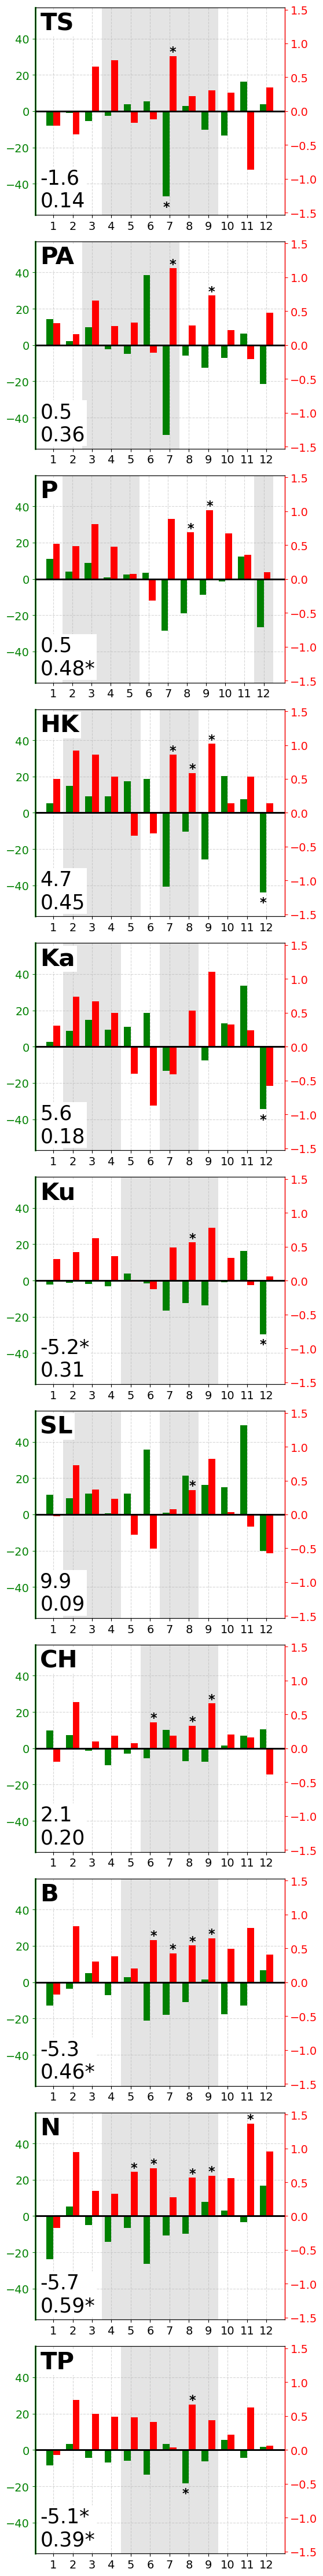

In [13]:
# letters for the subregions initials
letters = ['TS', 'PA', 'P', 'HK', 'Ka', 'Ku', 'SL', 'CH', 'B', 'N', 'TP']

# limites des ordonnées par variable
ylims = {}
for var in variables:
    all_slopes = []
    for dom in domains:
        all_slopes.extend([var_slopes2[var][dom][m] for m in months])
    ymin = min(all_slopes)
    ymax = max(all_slopes)
    margin = 0.075 * (ymax - ymin)
    ylims[var] = (ymin - margin, ymax + margin)

# figure
fig, axes = plt.subplots(11, 1, figsize=(5.5, 45))


for i, dom in enumerate(domains):

    ax = axes[i] # axe gauche = sf 
    ax2 = ax.twinx() # axe droit = t2m

    # saison d'accumulation de tp
    tp_months = tp_season[dom]
    tp_nums = [month_to_num[m] for m in tp_months]

    # sf trends stats
    slopes_sf = [var_slopes2['sf'][dom][m] for m in months]
    pvalues_sf = [var_pvalue2['sf'][dom][m] for m in months]

    # t2m trends stats
    slopes_t2m = [var_slopes2['t2m'][dom][m] for m in months]
    pvalues_t2m = [var_pvalue2['t2m'][dom][m] for m in months]

    # limites symétriques pour avoir le zéro au même endroit
    max_sf = max(abs(ylims['sf'][0]), abs(ylims['sf'][1]))
    max_t2m = max(abs(ylims['t2m'][0]), abs(ylims['t2m'][1]))
    ax.set_ylim(-max_sf, max_sf)
    ax2.set_ylim(-max_t2m, max_t2m)

    # offsets pour les étoiles (* = p-value < 0.05 = significatif)
    y_range_sf = 2 * max_sf
    offset_sf = 0.02 * y_range_sf
    y_range_t2m = 2 * max_t2m
    offset_t2m = 0.02 * y_range_t2m

    # ligne zéro
    ax.axhline(y=0,linestyle='-',linewidth=2,color='black',alpha=1,zorder=10)
    ax2.axhline(y=0,linestyle='-',linewidth=2,color='black',alpha=1,zorder=10)

    # barplot juxtaposé
    width = 0.35 # largeur des bars
    for m_idx, month_num in enumerate(range(1, 13)):

        # sf monthly trends - axe gauche
        p_sf = pvalues_sf[m_idx] # p-value
        val_sf = slopes_sf[m_idx] # slope
        ax.bar(month_num - width / 2,val_sf,width,color='green',alpha=1.0,edgecolor='none',zorder=3)
        if p_sf <= 0.05: # si la trend est significative (p<0.05)
            y_star = (val_sf + offset_sf if val_sf >= 0 else val_sf - (2.5 * offset_sf))
            ax.text(month_num - width / 2,y_star,'*',color='black',fontsize=16,fontweight='bold',ha='center',va='center',zorder=10)

        # t2m monthly trends - axe droit
        p_t2m = pvalues_t2m[m_idx]
        val_t2m = slopes_t2m[m_idx]
        ax2.bar(month_num + width / 2,val_t2m,width,color='red',alpha=1.0,edgecolor='none',zorder=3)
        if p_t2m <= 0.05:
            y_star = (val_t2m + offset_t2m if val_t2m >= 0 else val_t2m - (2.5 * offset_t2m))
            ax2.text(month_num + width / 2,y_star,'*',color='black',fontsize=16,fontweight='bold',ha='center',va='center',zorder=10)

    # shading gris pour tp months
    for m in tp_nums:
        ax.axvspan(m - 0.5,m + 0.5,color='lightgray',alpha=0.6,zorder=0,ec=None)

    # labels des mois
    # number associated with the month of the year 1 -> 12 (1=January, 12=December)
    x = np.arange(1,13)
    ax.set_xticks(range(1, 13))
    ax.tick_params(axis='x',labelsize=16)

    # axe gauche = sf = vert
    ax.tick_params(axis='y',which='both',labelleft=True,labelsize=16,labelcolor='green',left=True,colors='green')
    ax.spines['left'].set_color('green')
    ax.spines['left'].set_linewidth(2)
    
    
    # axe droit = t2m = rouge
    ax2.tick_params(axis='y',labelright=True,labelsize=16,labelcolor='red',colors='red')
    ax2.spines['right'].set_color('red')
    ax2.spines['right'].set_linewidth(1)

    # labelsize des ax-y & ax-x
    ax.tick_params(axis='y', labelsize=14)
    ax.set_xticklabels(x, fontsize=14)
    ax2.tick_params(axis='y', labelsize=14)
    
    # grille
    ax.grid(True,linestyle='--',alpha=0.5)

    # lettre de la sous-région
    ax.text(0.02,0.98,f'{letters[i]}',transform=ax.transAxes,fontsize=30,fontweight='bold',va='top',ha='left',
        bbox=dict(facecolor='white',edgecolor='none',alpha=1,pad=2),zorder=15)

    ax.text(0.02, 0.02,
            f"{data_annual['sf'].loc[data_annual['sf']['region'] == dom, 'slope'].values[0]:.1f}{'*' if data_annual['sf'].loc[data_annual['sf']['region'] == dom, 'pvalue'].values[0] <= 0.05 else ''}\n{data_annual['t2m'].loc[data_annual['t2m']['region'] == dom, 'slope'].values[0]:.2f}{'*' if data_annual['t2m'].loc[data_annual['t2m']['region'] == dom, 'pvalue'].values[0] <= 0.05 else ''}",
            transform=ax.transAxes,fontsize=25,va='bottom',ha='left',
            bbox=dict(facecolor='white', edgecolor='none', alpha=1, pad=2), zorder=15)

plt.tight_layout(rect=[0, 0.01, 1, 1]) # [left, bottom, right, top]
plt.show()

# Legend of the subplots

The legend represents a subplot but for the entire HMA regions. 

# Mean temperature and snowfall in HMA 

In [29]:
path = '/bettik/PROJECTS/pr-regional-climate/bricej/era5/monthly/'
files = {'t2m': 't2m_monthly_era5_1940-2025_NH_025x025.nc',
        'sf': 'sf_MA_1940-2025_ERA5.nc'}

### Snow Fall

#### Data

In [30]:
var = 't2m'
file = files[var]

data_var = xr.open_dataset(path + file)[var]
if var in ['t2m', 'tcwv', 'ivt', 'vimd']:
    data_var = data_var.rename({'valid_time': 'time','latitude':'lat','longitude':'lon'})
data_var = data_var.sel(time=slice(str(iyear),str(fyear)))
data_var = field_dom(data_var, 'MA')

#### Only in HMA contour

In [ ]:
# fonction pour selectionner que les données dans le contour d'HMA
def himap_hma(ds):
    """
    Extrait les données de ds à l'intérieur du contour global de la HMA
    (toutes les sous-régions HiMAP fusionnées).

    Parameters
    ----------
    ds : xarray.Dataset ou xarray.DataArray

    Returns
    -------
    ds_region : xarray.Dataset ou xarray.DataArray
        Données uniquement dans le contour, NaN ailleurs, découpées
        sur la boîte englobante pour alléger le jeu de données.
    """

    # Détection des noms de dimensions lat / lon
    lat_str, lon_str = '', ''
    for dim in ds.dims:
        if dim in ['lat', 'latitude', 'LAT']:
            lat_str = dim
        elif dim in ['lon', 'longitude', 'LON']:
            lon_str = dim

    if not lat_str or not lon_str:
        raise ValueError("Dimensions de latitude/longitude introuvables dans ds.")

    # Shapefile des sous-régions
    shp_path = '/bettik/PROJECTS/pr-regional-climate/bricej/HIMAP_grouped_regions/himap_grouped_regions.shp'
    shp = gpd.read_file(shp_path)

    if shp.crs != "EPSG:4326":
        shp = shp.to_crs("EPSG:4326")

    # Fusion de toutes les sous-régions en un seul contour
    contour = gpd.GeoDataFrame(geometry=[shp.geometry.union_all()], crs=shp.crs) # (geopandas < 1.0 : shp.geometry.unary_union)

    # gérer le problème des tout petits trous dans les régions regroupés
    def remove_holes(geom):
        # Cas polygone simple
        if isinstance(geom, Polygon):
            return Polygon(geom.exterior)
        # Cas multipolygon
        elif isinstance(geom, MultiPolygon):
            return MultiPolygon([Polygon(p.exterior) for p in geom.geoms])
        return geom
    contour["geometry"] = (contour.geometry.apply(remove_holes))

    # Masque précis
    regions = regionmask.Regions(contour.geometry.values)
    mask = regions.mask(ds)          # 0 dans le polygone, NaN ailleurs
    ds = ds.where(mask == 0)

    # Découpe sur la boîte englobante
    lonW, latS, lonE, latN = contour.total_bounds
    if ds[lat_str][0] > ds[lat_str][-1]:
        lat_slice = slice(latN, latS)   # latitudes décroissantes
    else:
        lat_slice = slice(latS, latN)   # latitudes croissantes

    ds_region = ds.sel({lat_str: lat_slice, lon_str: slice(lonW, lonE)})

    return ds_region

In [32]:
data = himap_hma(data_var)

#### Monthly trend in HMA contour 

In [37]:
months = range(1,13)
trend_monthly_t2m = {}

for month in months:
    monthly_selection_var = seasonal_selection2(data, season_months=[month], iyr=iyear, fyr=fyear) # monthly slection
    data_monthly = monthly_selection_var.mean(dim=['lat','lon'], skipna=True) # spatial mean
    trend_monthly_t2m[month] = stats.linregress(data_monthly.time.values,data_monthly.values) # trend of the month wanted
    print(month)

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
1
2
3
4
5
6
7
8
9
10
11
12


In [ ]:
mean_val = data_monthly.mean(skipna=True).item()

if mean_val != 0: # vérification si la mean value est diffférent de zéro
    slope_pct = (trend_monthly_t2m[month].slope / mean_val) * 100
    stderr_pct = (trend_monthly_t2m[month].stderr / mean_val) * 100

else: # mettre NaN si mean value est égal à zéro
    slope_pct = np.nan
    stderr_pct = np.nan

trend_percentage[dom] = {
    'slope': slope_pct,
    'intercept': trend_monthly_t2m[month].intercept,
    'rvalue': trend_monthly_t2m[month].rvalue,
    'pvalue': trend_monthly_t2m[month].pvalue,
    'stderr': trend_monthly_t2m[month].stderr}